# 04. Corte de avance — Fine-tuning y análisis de errores de ResNet50

Clasificación de defectos superficiales de palta Hass: PICADURA y RUSSET  
Maestría en Inteligencia Artificial — Trabajo de Investigación  
Fecha de corte: 25 de octubre de 2026

**Propósito:** documentar el avance desde los experimentos B0, V1, D1 y D2 hasta FT_B0, FT_D1 y la identificación de errores de clasificación.

Este notebook es un **reporte independiente de lectura**. Sus tablas y gráficas están incluidas; no requiere ejecutar celdas y no modifica el dataset ni los resultados del entrenamiento.

**Estado del proyecto en este corte:** FT_D1 finalizado; análisis cuantitativo de 16 errores realizado; inspección visual de las imágenes erradas, pendiente.


## 1. Resumen ejecutivo

- Se completaron **seis condiciones experimentales** basadas en ResNet50: B0, V1, D1, D2, FT_B0 y FT_D1.
- El mejor resultado observado en **validation** corresponde a **FT_D1**, con **accuracy = 87.40 %**, **macro-F1 = 0.7524** y **recall RUSSET = 52.38 %**.
- FT_D1 acertó **111 de 127** imágenes; confundió **6 PICADURA con RUSSET** y **10 RUSSET con PICADURA**.
- La menor pérdida de validación de FT_D1 ocurrió en la **época 4** (val_loss = **0.3529**), aunque se ejecutaron 8 épocas. El mejor checkpoint se guardó.
- El análisis de errores mostró **3 predicciones incorrectas con puntuación softmax ≥ 90 %**; las tres corresponden a RUSSET clasificadas como PICADURA.

La evidencia es preliminar: la validación contiene solo 21 casos RUSSET y aún no se ha realizado la evaluación final sobre test.


## 2. ¿Qué significan los experimentos?

| Código | Significado | Diferencia principal respecto al modelo de referencia |
|:---|:---|:---|
| **B0** | Baseline | ResNet50 con extractor ImageNet congelado; entrada de 256 × 512 píxeles; sin augmentation. |
| **V1** | Variante de resolución | Igual protocolo de B0, con entrada de 384 × 768 píxeles. |
| **D1** | Variante de datos 1 | Una copia fotométricamente aumentada por imagen RUSSET de train: 77 copias adicionales. |
| **D2** | Variante de datos 2 | Dos copias aumentadas por RUSSET de train: 154 copias adicionales. |
| **FT_B0** | Fine-tuning de B0 | Parte del entrenamiento B0 y ajusta parcialmente el bloque `conv5` de ResNet50. |
| **FT_D1** | Fine-tuning de D1 | Parte del entrenamiento D1 y ajusta parcialmente `conv5`, combinando ajuste fino y aumento de datos. |

En D1 y D2 se conserva el TIFF completo con sus tres franjas y la secuencia de vistas. Las variaciones fotométricas se aplican solo a train, no a validation ni test.


## 3. Dataset, integridad y entorno de ejecución

El dataset contiene **829 archivos TIFF** de paltas. Cada TIFF corresponde a una unidad de análisis y reúne tres franjas horizontales de captura, una por cámara; las vistas de una misma palta no se tratan como muestras independientes.

| Conjunto | PICADURA original | RUSSET original | Total original | Archivos elegibles |
|:---|---:|---:|---:|---:|
| Train | 497 | 77 | 574 | 572 |
| Validation | 107 | 21 | 128 | 127 |
| Test | 106 | 21 | 127 | 126 |
| **Total** | **710** | **119** | **829** | **825** |

La auditoría comparó los hashes SHA-256 de los 829 archivos con el inventario del EDA y aplicó **cuatro exclusiones lógicas**, asociadas con dos pares exactos entre particiones. No se borraron los TIFF.

La ejecución actual se realizó en **VS Code + Ubuntu WSL2**, con **Python 3.12**, **TensorFlow 2.21** y la GPU **NVIDIA RTX 3070 Ti Laptop GPU**. Se comprobó que TensorFlow detectó `GPU:0`.

**Límite metodológico:** eliminar coincidencias exactas no demuestra por sí solo independencia por fruto, lote o sesión de adquisición. La trazabilidad por fruto/lote sigue pendiente de verificación adicional.


## 4. Configuración del ajuste fino

Para comparar FT_B0 y FT_D1 se utilizaron las siguientes condiciones iniciales:

| Parámetro | Configuración |
|:---|:---|
| Red base | ResNet50 preentrenada en ImageNet |
| Capas ajustadas | Bloque final `conv5` y cabeza de clasificación; BatchNormalization congelada |
| Épocas máximas | 8 |
| Lote (`batch size`) | 1 imagen |
| Tasa de aprendizaje | `1e-5` |
| Selección de pesos | Menor pérdida de validación |
| Conjunto para comparar modelos | Validation (127 TIFF elegibles) |
| Test | Reservado; no utilizado para elegir las variantes |

Se eligieron 8 épocas como prueba inicial conservadora, no como un valor óptimo establecido. Se utilizó un lote pequeño por el mayor uso de memoria GPU que implica actualizar capas profundas. FT_D1 parte de `D1_s42_03` y FT_B0 parte de `B0_s42_01`.


## 5. Comparación de los seis experimentos

Todos los valores corresponden al mismo conjunto de validation de 127 TIFF elegibles.

| Experimento | Accuracy | Macro-F1 | Recall RUSSET | Aciertos RUSSET |
|:---|---:|---:|---:|---:|
| B0 | 84.25 % | 0.6604 | 33.33 % | 7/21 |
| V1 | 85.83 % | 0.6598 | 28.57 % | 6/21 |
| D1 | 84.25 % | 0.7033 | 47.62 % | 10/21 |
| D2 | 85.83 % | 0.6944 | 38.10 % | 8/21 |
| FT_B0 | 86.61 % | 0.7183 | 42.86 % | 9/21 |
| **FT_D1** | **87.40 %** | **0.7524** | **52.38 %** | **11/21** |

FT_D1 supera a B0 en **0.0920 de macro-F1** y **19.05 puntos porcentuales de recall RUSSET**. Frente a D1, la mejora de FT_D1 es de **0.0491 de macro-F1** y **un acierto más de RUSSET**. Estas diferencias son descriptivas, sin intervalos de confianza ni repeticiones de semillas.


### Gráfica: Macro-F1


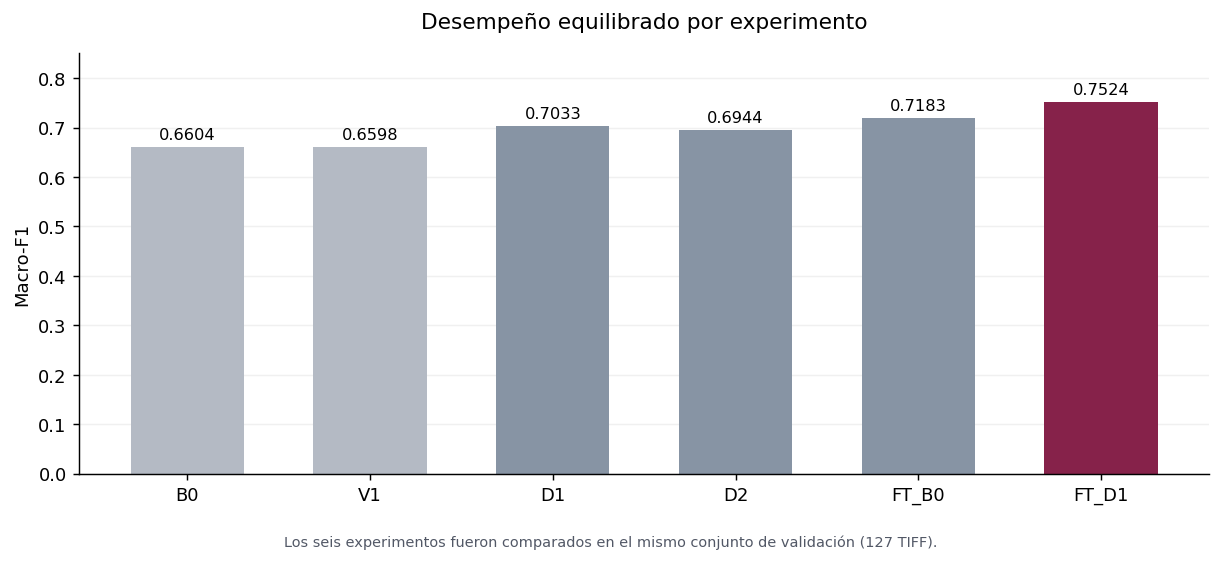

*Barras construidas exclusivamente a partir de las métricas reales de validation de los seis experimentos.*


### Gráfica: Recall de RUSSET


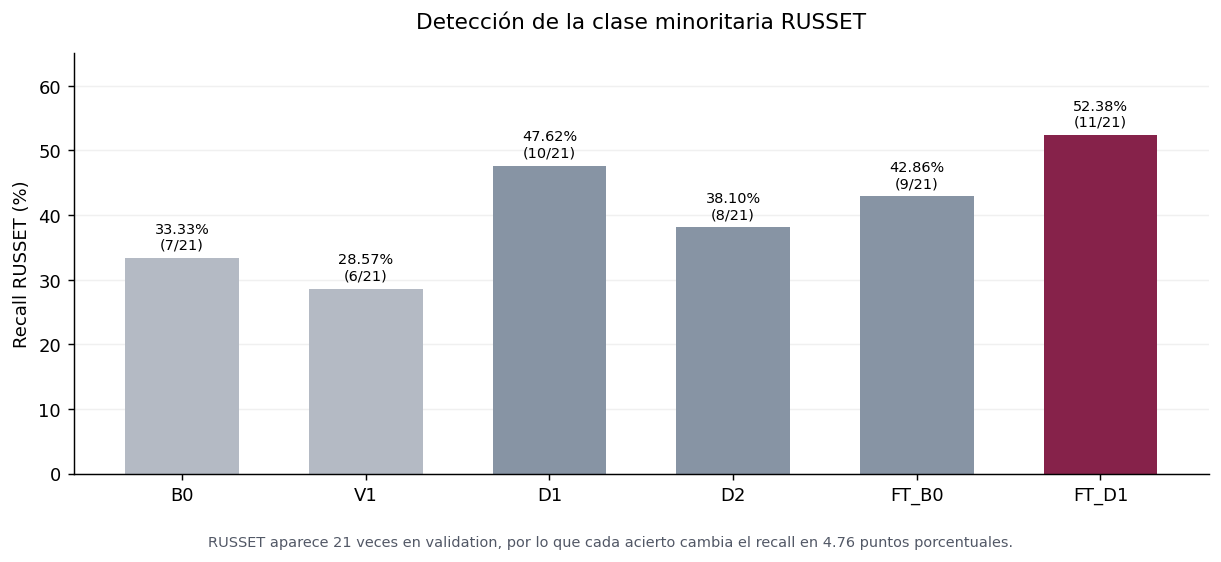

*La proporción de RUSSET correctamente clasificada pasa de 7/21 (B0) a 11/21 (FT_D1).*


## 6. Evaluación detallada de FT_D1

La matriz de confusión de FT_D1, con filas de clase real y columnas de predicción, es:

| Clase real / Predicción | PICADURA | RUSSET | Total real |
|:---|---:|---:|---:|
| PICADURA | **100** | 6 | 106 |
| RUSSET | 10 | **11** | 21 |
| **Total** | **110** | **17** | **127** |

| Métrica | PICADURA | RUSSET |
|:---|---:|---:|
| Precision | 0.9091 | 0.6471 |
| Recall | 0.9434 | 0.5238 |
| F1-score | 0.9259 | 0.5789 |
| Cantidad real | 106 | 21 |

El **accuracy global es 111/127 = 87.40 %** y el **macro-F1 es 0.7524**. Por cada 21 casos reales de RUSSET, el modelo detecta 11 y deja pasar 10. La mejora global no elimina la dificultad de reconocer la clase minoritaria.


### Evidencia: salida real de FT_D1 en Jupyter


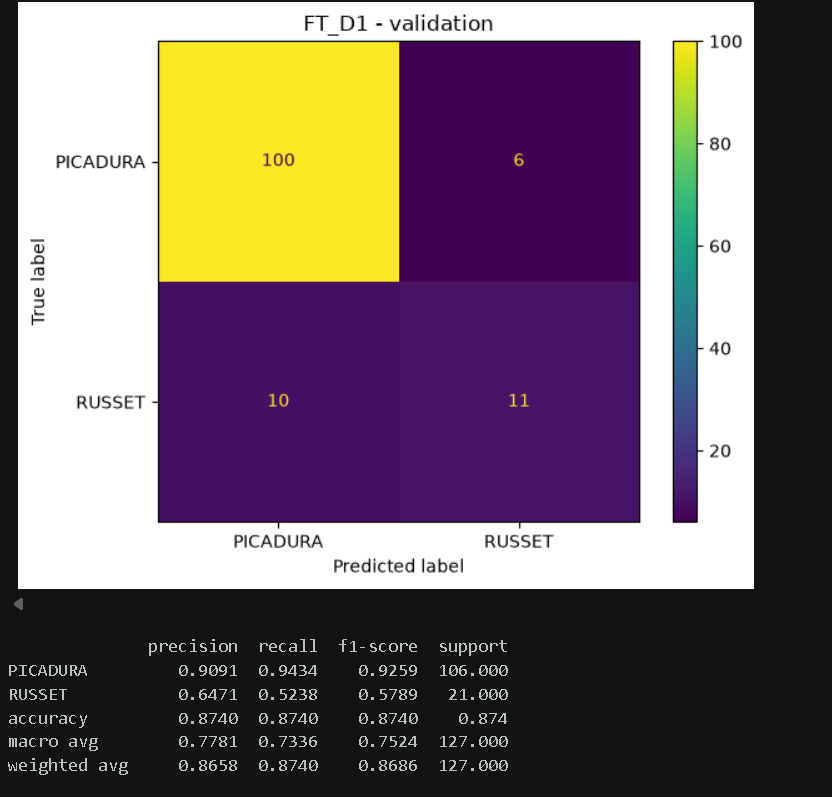

*Captura del resultado real de FT_D1: matriz de confusión y reporte de clasificación.*


## 7. Aprendizaje, mejor época y posible sobreajuste

Se ejecutaron **8 épocas** de fine-tuning y se verificó posteriormente el archivo del historial:

| Indicador | Resultado comprobado |
|:---|:---|
| Estado del experimento | `entrenamiento_completo` |
| Épocas registradas | 8 |
| **Mejor época por `val_loss`** | **4** |
| **Pérdida mínima en validation** | **0.3529** |
| Pesos del mejor checkpoint | `mejor_finetune.weights.h5` existente |

La curva de entrenamiento muestra que la pérdida de train continúa disminuyendo y su accuracy se aproxima al 100 %. En cambio, la pérdida de validation vuelve a aumentar después de la época 4 y fluctúa con valores elevados. El patrón es compatible con **sobreajuste y predicciones incorrectas muy seguras**, pero debe confirmarse con más datos y semillas.

No debe confundirse **la última época entrenada** con **la época cuyos pesos se conservaron**. La evaluación de FT_D1 se realizó después de recuperar los pesos guardados como mejor checkpoint.


### Evidencia: pérdida durante el fine-tuning


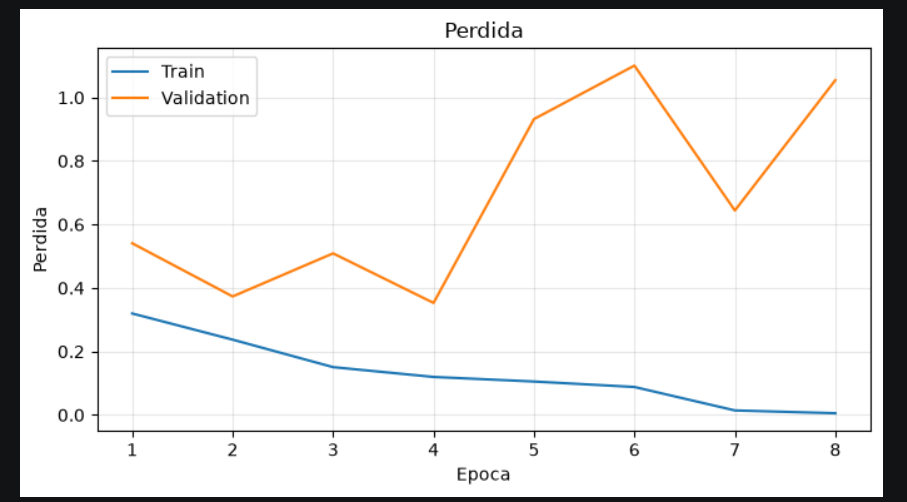

*Curvas reales de pérdida de train y validation: mínimo de validation alrededor de la época 4.*


### Evidencia: accuracy durante el fine-tuning


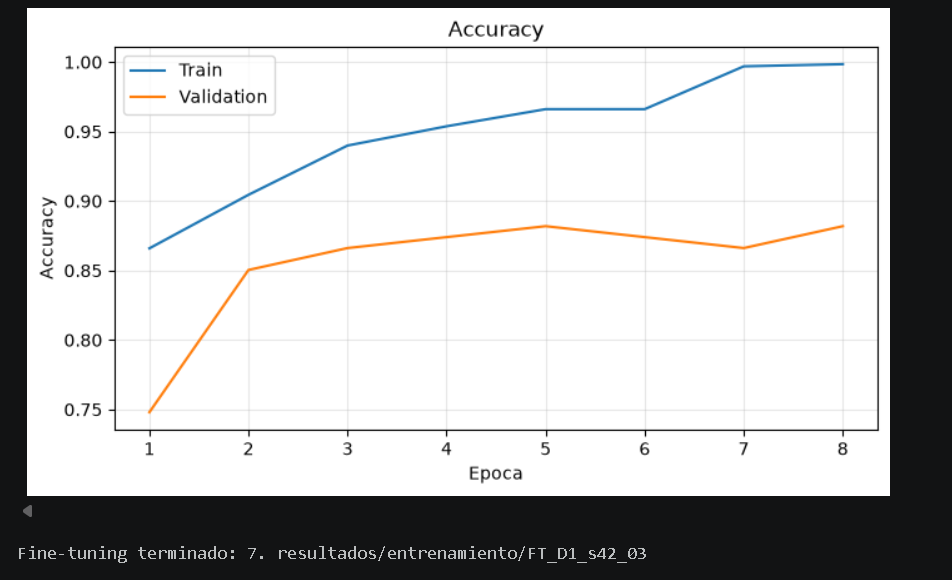

*Curvas reales de accuracy; la separación train/validation aumenta hacia el final.*


## 8. Análisis cuantitativo de errores de FT_D1

Se utilizó el CSV de predicciones del experimento `FT_D1_s42_03` y se filtraron los casos donde la clase real no coincide con la predicción. El análisis **no modificó imágenes** y generó un CSV adicional.

| Resultado | Cantidad |
|:---|---:|
| Imágenes evaluadas | 127 |
| Correctamente clasificadas | 111 |
| **Total de errores** | **16** |
| PICADURA → predicha RUSSET | 6 |
| RUSSET → predicha PICADURA | 10 |
| **Errores con puntuación de predicción ≥ 90 %** | **3** |

Los tres errores por encima del 90 % corresponden a **RUSSET clasificadas como PICADURA**. Este resultado orienta la inspección visual hacia falsos negativos de RUSSET con alta puntuación para la clase contraria.

La columna `confianza_prediccion` se obtuvo tomando la **salida softmax de la clase predicha**. No debe interpretarse automáticamente como una probabilidad calibrada de acierto.


### 8.1. Errores con puntuaciones más altas

Se muestran identificadores **abreviados** tal como pueden localizarse en la captura. Las rutas completas se conservan en `analisis_errores_validation.csv`.

| Identificador abreviado | Clase real → Predicción | Puntuación de la predicción |
|:---|:---|---:|
| `…091147-3` | RUSSET → PICADURA | 97.76 % |
| `…091252-7` | RUSSET → PICADURA | 93.17 % |
| `…091137-9` | RUSSET → PICADURA | 90.50 % |
| `…162723-7` | PICADURA → RUSSET | 89.56 % |
| `…091156-4` | RUSSET → PICADURA | 89.53 % |
| `…091247-6` | RUSSET → PICADURA | 88.24 % |
| `…162758-9` | PICADURA → RUSSET | 87.37 % |
| `…113806-7` | PICADURA → RUSSET | 75.45 % |

**Lectura:** el primer caso es un RUSSET real que FT_D1 clasificó como PICADURA con una puntuación softmax de 0.977581. Es un error de alta puntuación, no evidencia de que el sistema esté calibrado a una confianza estadística del 97.76 %.


### Evidencia: tabla real de errores ordenados


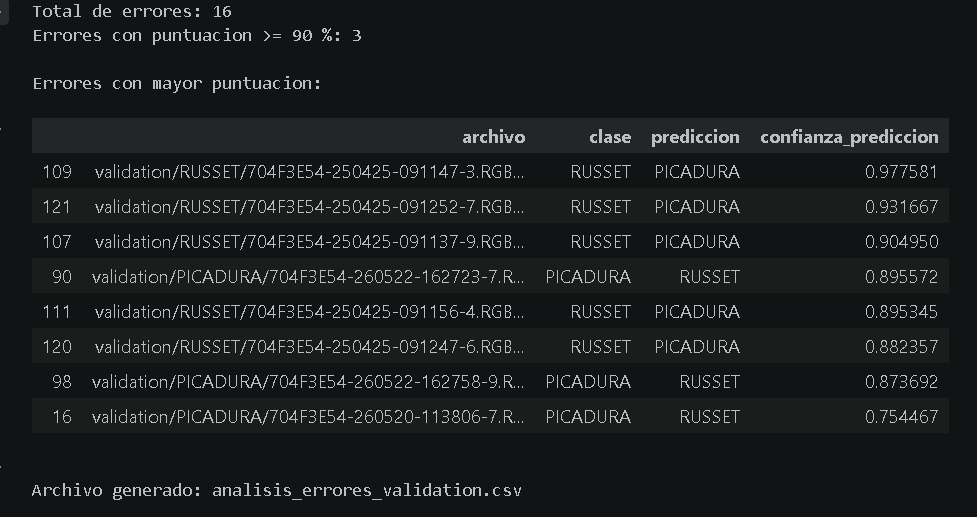

*Captura de la tabla generada: 16 errores identificados, 3 con puntuación ≥ 90 % y sus primeros ocho registros.*


## 9. Interpretación técnica de los hallazgos

1. **Balanceo de datos:** D1 mejora el recall de RUSSET frente a B0; D2 no produce una mejora adicional, lo que indica que generar más copias no garantiza mayor rendimiento.
2. **Fine-tuning:** FT_D1 aporta el macro-F1 más alto observado, por encima de D1 y de FT_B0.
3. **Persistencia de errores:** pese a la mejora, 10 de los 21 RUSSET reales se clasifican como PICADURA, lo que exige una revisión específica de los falsos negativos.
4. **Puntuaciones elevadas en errores:** hay 3 casos de RUSSET incorrectamente clasificados con puntuación softmax igual o superior a 0.90; conviene revisar visualmente sus tres franjas y condiciones de captura.
5. **Generalización:** las curvas de FT_D1 muestran una separación importante entre entrenamiento y validación tras la época 4; se deberá contrastar con repeticiones y un protocolo de selección de checkpoint claro.

**Todavía no se ha demostrado** que los errores procedan de la iluminación, textura, similitud entre defectos o cámaras. Son hipótesis que deberán verificarse al inspeccionar los TIFF completos y la información de procedencia.


## 10. Pendientes para la siguiente sesión

1. Abrir los TIFF completos de los **3 errores de RUSSET con puntuaciones ≥ 90 %**, conservando las tres franjas y todas las vistas de cada palta.
2. Revisar los **16 errores** y clasificarlos por observaciones visuales documentadas: tipo de textura, iluminación, zona defectuosa, fondo y posible ambigüedad de etiqueta, sin asignar causas antes de inspeccionar las imágenes.
3. Revisar si existen frutos, lotes o sesiones relacionadas a través de diferentes particiones; disponer de trazabilidad más allá de coincidencias exactas.
4. Repetir el protocolo con otras semillas o estimar incertidumbre, manteniendo validation para comparar modelos y **test reservado** hasta fijar la metodología.
5. Examinar alternativas de regularización, parada anticipada y calibración de puntuaciones si los resultados lo justifican.
6. Actualizar el informe final con matrices, curvas y análisis de errores, distinguiendo resultados confirmados de hipótesis.

**No se propone reentrenar todavía:** el siguiente paso es examinar visualmente los errores y registrar evidencias.


## 11. Ubicación de los archivos y conservación de resultados

El notebook principal de entrenamiento debe permanecer en:

`6. entrenamiento/resnet50.ipynb`

Resultados conservados:

- `7. resultados/entrenamiento/B0_s42_01/`
- `7. resultados/entrenamiento/D1_s42_03/`
- `7. resultados/entrenamiento/D2_s42_01/`
- `7. resultados/entrenamiento/FT_B0_s42_01/`
- `7. resultados/entrenamiento/FT_D1_s42_03/`

Dentro de `FT_D1_s42_03/`:

- `historial.csv`: registro de las ocho épocas.
- `predicciones_validation.csv`: predicciones por imagen.
- `analisis_errores_validation.csv`: tabla de 16 errores ordenados por puntuación de la predicción.
- `mejor_finetune.weights.h5`: pesos del checkpoint elegido por validación.

**Recomendación de archivo:** guardar este corte como `1. fuentes/04_Analisis_Errores_ResNet50.ipynb`, después del corte `03_Corte_Avance_ResNet50_B0_V1_D1_D2.ipynb`.

Al archivar el notebook principal, mantener `ENTRENAR = False` y `EJECUTAR_FT = False` para impedir ejecuciones involuntarias. El reporte actual contiene todas sus imágenes embebidas y no necesita acceso a las carpetas de resultados para poder leerse.


---

**Procedencia de los resultados:** tablas y salidas compartidas de las ejecuciones del notebook `resnet50.ipynb`, auditoría EDA, métricas de validation, historial de FT_D1 y CSV de análisis de errores generados durante esta sesión. Las capturas y gráficos incluidos corresponden a esos resultados. No se presentan métricas de test ni se afirma una evaluación externa independiente.

**Fin del corte 04.**
